# DOOMSCROLL
## End-to-End Recommender Systems Project Report

**Project repository:** [github.com/1ens0r/doomscroll](https://github.com/1ens0r/doomscroll)  
**Dataset:** KuaiSAR-v2 short-video interaction logs  
**Report scope:** Exploratory data analysis, data preparation, engagement ranking, simulated users, feed-policy experiments, composer evaluation and evolutionary optimisation.

---

### Abstract

Doomscroll studies a complete short-video recommendation loop. It begins with millions of real interaction records, constructs temporally valid features, trains a compact engagement ranker, and places the ranker inside a synthetic environment containing 10,000 simulated users. Competing feed policies are evaluated on both a project-defined well-being proxy and guardrails such as catalog coverage, category diversity and repeat exposure. The final system combines offline ranking with a calibrated-but-imperfect behavioural simulator and a staged policy search.

The repository reports a test NDCG@10 of **0.5332** for the wide TasteNet model, compared with **0.4976** for popularity. In the simulator, the evolved policy reaches **151.53 IWE per bot** in the Phase-A ladder, compared with **61.86** for random and **213.10** for an adaptive oracle ceiling. These results are evidence of relative improvements under the repository's evaluation setup, not proof of causal improvement in real-world well-being.

> **Reproducibility and provenance.** This notebook is a self-contained, presentation-ready report with repository-documented results and report figures embedded as notebook outputs. It does not claim that the raw KuaiSAR-v2 dataset or a fresh model-training run was executed in this authoring environment. Metric values are explicitly labelled as reported repository results. Source code and experiment commands are linked to the public repository.

## 1. Project objectives

The project addresses two connected problems.

1. **Offline ranking:** given a user, candidate video and context, rank videos by graded engagement rather than treating every click as equally valuable.
2. **Closed-loop policy evaluation:** test how the ranking model behaves when it determines a sequence of videos, user reactions, session continuation and future feedback.

A high offline ranking score alone cannot establish that an entire feed is useful. A policy can maximise clicks while narrowing the content mix or repeatedly showing similar items. The simulator therefore compares policies using an aggregate IWE score and explicit guardrails.

### End-to-end workflow

1. Load and clean raw interaction logs.
2. Explore engagement labels, user activity, item popularity, timing, sessions, search and novelty.
3. Construct as-of features and strictly temporal train/validation/test partitions.
4. Train TasteNet using masked multi-action supervision and a ranking-aware objective.
5. Evaluate against random, popularity and personal-affinity baselines.
6. Build a synthetic world of users, items and response dynamics.
7. Calibrate the response model and check online/offline feature parity.
8. Evaluate a ladder of feed policies using common random numbers.
9. Test composer adjustments, preserve negative results, and evolve policy parameters.
10. Interpret results with uncertainty and limitations.

## 2. Repository architecture

The public repository separates the analysis, engine and experiment documentation.

| Component | Responsibility |
|---|---|
| `eda/` | Data exploration notebooks and generated EDA figures |
| `recommender-engine/prepare_data.py` | Canonical raw-data preparation entry point |
| `recommender-engine/feed/build.py` | Feature-table construction |
| `recommender-engine/feed/data.py` | Data loading and transformations |
| `recommender-engine/feed/model.py` | TasteNet architecture |
| `recommender-engine/feed/train.py` | Model training |
| `recommender-engine/feed/eval.py` | Ranking evaluation and baselines |
| `recommender-engine/feed/world.py` and `content.py` | Synthetic user/content world |
| `recommender-engine/feed/response.py` | Simulated user response and session dynamics |
| `recommender-engine/feed/policies.py` | Retrieval and ranking policies |
| `recommender-engine/feed/composer.py` | Re-ranking adjustments |
| `recommender-engine/feed/swarm.py` | Multi-bot lockstep simulation |
| `recommender-engine/feed/metrics.py` | IWE and guardrail metrics |
| `recommender-engine/feed/evolve.py` | Evolutionary policy search |
| `recommender-engine/run_offline.py` | Offline evaluation driver |
| `recommender-engine/run_swarm.py` | Policy ladder driver |
| `recommender-engine/run_generations.py` | Composer experiment driver |
| `recommender-engine/run_evolve.py` | Evolution experiment driver |
| `notes/` | Phase reports, calibration findings, assumptions and diagnostics |
| `demo.ipynb` | Repository's original end-to-end executed demonstration |

The repository README recommends the original `demo.ipynb` as the executable walkthrough. This report consolidates the project story and its documented results into a submission-style narrative.

## 3. Dataset and data preparation

The project uses KuaiSAR-v2, a short-video interaction dataset. Each impression records that a user was shown a video at a particular time, with available action and watch-related signals.

### 3.1 Reported data scale

| Quantity | Repository-reported value |
|---|---:|
| Raw interactions | 19.66 million |
| Events after exact deduplication | 19.61 million |
| Exact duplicates removed | 48,257 |
| Raw users | 25,877 |
| Raw items/videos | 6.89 million |
| Categories | 38 |
| Observation window | 19.1 days |
| Rows after 5/3 k-core filtering | 13,061,273 |
| Modelled training rows | 2,612,256 |
| Modelled validation rows | 1,959,189 |
| Modelled test rows | 1,959,194 |
| Final as-of feature count (status report) | 43 |

The README and phase status summarise different points in the pipeline. The counts above preserve the repository's distinction between raw, deduplicated, k-core-filtered and modelled data.

### 3.2 Why clean and filter?

- **Exact deduplication** prevents repeated copies of the same event from receiving excess weight.
- **K-core filtering** removes users and items with insufficient interactions for reliable feature statistics.
- **Temporal splitting** evaluates on later impressions instead of mixing future information into the past.
- **As-of features** ensure that the model only uses information that would have been available at the time of recommendation.

The k-core filter improves learnability but removes much of the item long tail. This creates a cold-start challenge, which the later system handles with category-level fallback and item priors.

## 4. Graded engagement labels

Doomscroll uses an ordinal `label_tier` from 0 to 4. Tier 0 represents no engagement; larger tiers encode stronger signals. The repository reports an imbalanced distribution: roughly 48% tier 0, 46% tier 1, and a small high-intent tail across tiers 2–4.

A click is not equivalent to a like, follow, forward or long watch. A binary target would collapse weak and strong signals into one class. Graded relevance lets the ranker distinguish these outcomes and lets NDCG reward stronger interactions more heavily.

A crucial missing-label rule applies to search impressions: search logs clicks only. If like/follow/forward/watch outcomes are not recorded for those rows, those targets are **unobserved**, not negative. The model masks these labels during training rather than fabricating false negatives.

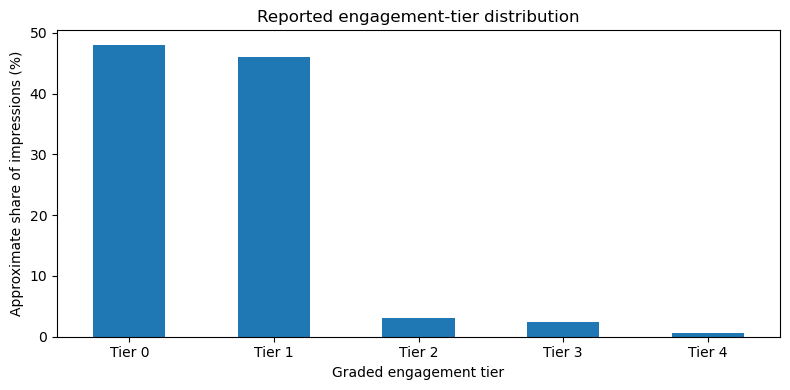

In [2]:
# Visualise the repository-reported approximate tier distribution.
import pandas as pd
import matplotlib.pyplot as plt

tier_share = pd.Series(
    [48.0, 46.0, 3.0, 2.4, 0.6],
    index=["Tier 0", "Tier 1", "Tier 2", "Tier 3", "Tier 4"]
)
ax = tier_share.plot(kind="bar", figsize=(8, 4), title="Reported engagement-tier distribution")
ax.set_ylabel("Approximate share of impressions (%)")
ax.set_xlabel("Graded engagement tier")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 5. Exploratory data analysis

EDA is used to motivate modelling and policy choices. The repository's committed EDA gallery includes action rates, action co-occurrence, watch behaviour, feature viability, feature deciles, feature correlation, user activity, cohorts, interest concentration, item popularity, category representation, temporal patterns, sessions, search-versus-feed behaviour, repeat novelty and cleaning diagnostics.

### 5.1 Action rates

The repository reports a click rate near 50%, like rate near 3%, follow rate near 0.4% and forward rate near 0.3%. The much smaller downstream-action rates motivate multi-action learning with masking and a graded relevance target.

### 5.2 Watch-time behaviour

Watch fraction is a denser signal than rare explicit actions. The EDA describes a bimodal pattern: many impressions are skipped almost immediately, while another group is watched close to completion. Tier-0 impressions tend to have low watch fraction; tier-1-and-above impressions tend to show much larger watch fractions.

Watch time remains a behavioural proxy. It does not, by itself, prove satisfaction or well-being.

### 5.3 Feature viability

The README reports strong individual features such as `u_pos_rate` (ROC-AUC around 0.68), `u_mean_score` (around 0.66) and `u_play_ratio` (around 0.63). The feature-group ordering is reported as user > user-category > item > context. No individual feature is sufficient, so the model combines multiple groups.

### 5.4 User activity inequality

The median user has approximately 223 events. Activity is long-tailed, with a reported Gini coefficient around 0.63. The top 1% of users generate roughly 12% of events and the top 10% around 48%. User-normalised features are therefore important; global averages would obscure individual differences.

### 5.5 Item popularity

Exposure is highly concentrated: the top 1% of videos receive about 20% of impressions. However, log exposure and engagement rate correlate only weakly (reported correlation around 0.13). Popularity is a useful baseline, but it is not a reliable substitute for personalised ranking.

### 5.6 Timing, sessions, search and novelty

- Impression volume peaks around 20:00–21:00, while engagement is reported to peak nearer midday.
- Sessions are short and front-loaded: early impressions influence whether the user continues.
- Search represents around 15% of events and roughly 97% of users search at least once.
- Feed engagement is reported to be 6–10 percentage points higher after a recent search in the same category.
- Engagement declines sharply on repeat exposure; novelty and recency therefore matter.
- Users cover many categories, creating a trade-off between exploiting known interests and preserving variety.

These observations motivate user-normalised features, cyclical time features, search-context features, cold-item handling, session modelling and diversity-aware composition.

## 6. Feature engineering and leakage prevention

The feature system combines four groups:

1. **User history:** engagement habits and preference summaries.
2. **Item/video priors:** exposure and quality estimates.
3. **User-category affinity:** historical engagement with content categories.
4. **Pair/context features:** compatibility between a user and candidate video, plus contextual signals such as time and recent search.

The model's features are calculated as of each impression timestamp. Train-derived transformations are fit on training data and then applied unchanged to validation and test. This avoids letting future outcomes affect predictions for past impressions.

The repository status reports 43 leakage-free as-of features in the final data layer. Earlier phases may show a smaller feature count because the pipeline evolved; counts must be attributed to the appropriate phase.

## 7. TasteNet: model architecture

The final wide TasteNet is a compact multi-tower neural network with 122,773 parameters and CPU training.

| Tower/component | Reported design |
|---|---|
| User tower | 9 user features, hidden dimensions 128 → 64 |
| Video tower | 5 video features plus 24-dimensional category embedding, hidden dimensions 128 → 64 |
| Pair tower | 13 user/video/context interaction features, hidden dimension 64 |
| Interaction | Element-wise product of user and video representations |
| Fusion head | Concatenated representations → 128 → 5 action logits |
| Output actions | Click, like, follow, forward and watch |

The repository also documents an earlier TasteNet with approximately 32,357 parameters. That earlier checkpoint and the final wide model are separate experiment phases.

## 8. Training objective

The final model combines two learning signals:

- **Masked binary cross-entropy (BCE):** trains action-specific probability heads while ignoring unobserved targets.
- **LambdaRank-style ranking term:** encourages higher-tier items to be ranked above lower-tier items for the same user.

The ranking-aware objective is aligned with the final use case: ordering a feed. The README reports validation NDCG@10 of 0.5119 for the LambdaRank ablation compared with 0.4961 for the masked-BCE reference. The final long run reports best validation NDCG@10 of 0.5143.

### Why NDCG@10?

Normalized Discounted Cumulative Gain evaluates the ordering of the top-ranked items and supports graded relevance. Stronger engagement tiers receive greater gain, and items near the top of the list matter more than items far down the list. This makes NDCG@10 more informative than plain accuracy for a ranked feed.

## 9. Offline evaluation

The model is compared against four main references:

- **Random ranking:** a sanity baseline.
- **Popularity:** ranks items by global popularity.
- **Personal affinity:** ranks using user-specific preference signals.
- **TasteNet:** learns a ranking from user, item, category and context features.

A LightGBM reference appears in the earlier phase report as a stronger tabular ceiling. The final wide model and earlier 32k model should not be conflated.

### 9.1 Reported ranking results

The following table uses the final README's headline wide-model result and the status report's earlier baseline values. These are repository-reported metrics, not results newly trained in this notebook.

,Method,Validation NDCG@10,Test NDCG@10
0,Random,0.4293,0.4407
1,Popularity,0.4766,0.4976
2,Personal affinity,0.4822,0.5013
3,"TasteNet — wide, final",0.5143,0.5332


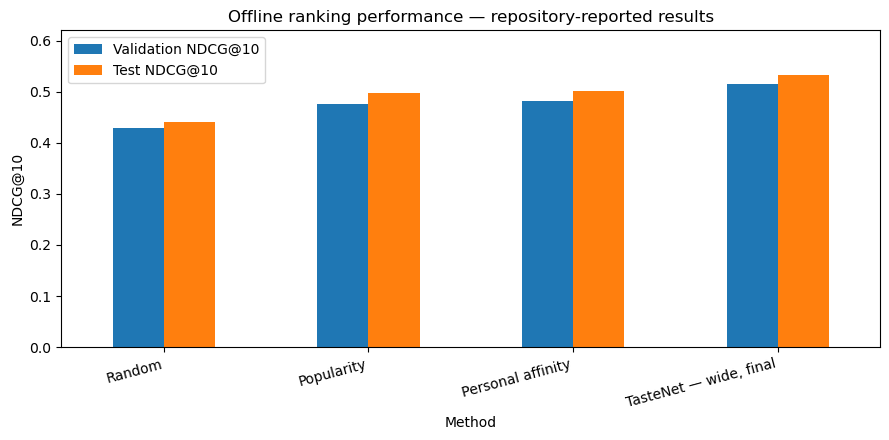

In [3]:
# Repository-reported offline ranking results.
# These values are transcribed from the README/status reports, not freshly trained here.
import pandas as pd
import matplotlib.pyplot as plt

offline_results = pd.DataFrame([
    {"Method": "Random", "Validation NDCG@10": 0.4293, "Test NDCG@10": 0.4407},
    {"Method": "Popularity", "Validation NDCG@10": 0.4766, "Test NDCG@10": 0.4976},
    {"Method": "Personal affinity", "Validation NDCG@10": 0.4822, "Test NDCG@10": 0.5013},
    {"Method": "TasteNet — wide, final", "Validation NDCG@10": 0.5143, "Test NDCG@10": 0.5332},
])
display(offline_results)
ax = offline_results.set_index("Method").plot(kind="bar", figsize=(9, 4.5))
ax.set_title("Offline ranking performance — repository-reported results")
ax.set_ylabel("NDCG@10")
ax.set_ylim(0, 0.62)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

### 9.2 Statistical uncertainty

The README reports test NDCG@10 of 0.5332 for TasteNet and 0.4976 for popularity, an absolute gain of **0.0356**. The paired-bootstrap 95% confidence interval is **[0.0327, 0.0384]**, excluding zero. This supports a reliable offline ranking improvement under the held-out evaluation.

The result does not, by itself, prove that a complete feed improves well-being. That requires evaluating the closed-loop policy, and even the simulator can only support conclusions under its assumptions.

## 10. Synthetic world and bot population

The second half of Doomscroll simulates a feed as a sequential system. The engine creates 10,000 synthetic users and runs them over seven days. A bot is a controlled simulated profile, not a real individual.

The simulator models:
- latent interests and category affinities;
- video category and quality/appeal;
- previous exposures and repetition;
- time context;
- click and downstream-action probabilities;
- watch duration and session continuation;
- user return/leave dynamics.

The main components include `feed/world.py`, `feed/content.py`, `feed/featurestate.py`, `feed/response.py`, `feed/policies.py`, `feed/metrics.py`, `feed/swarm.py` and `feed/parity.py`.

## 11. Calibration and feature parity

Calibration checks whether the simulated population reproduces selected real-data behavioural marginals. The repository reports that **7 of 12 targets** fall within a 15% relative-error band. Five structural misses remain, including the overnight trough, second/third repeat exposure, one-item-session engagement and very long-session engagement.

Feature parity checks whether user-side features computed online in the simulator match the offline feature definitions. The status report records **13/13 parity checks passing** within the project's stated tolerance.

These results should be reported together. Passing feature parity is a valuable engineering check, but it does not mean the simulated behavioural model is perfectly calibrated. The simulator remains hand-designed and imperfect.

## 12. Feed-policy ladder

The policy ladder compares progressively more capable strategies:

1. **Random:** no meaningful personalisation.
2. **Popularity:** global popularity ranking.
3. **Personal affinity:** user-specific preference ranking.
4. **Taste:** learned engagement ranker.
5. **Taste composer:** learned ranker plus controlled re-ranking.
6. **Evolved:** parameters tuned by evolutionary search.
7. **Oracle:** adaptive greedy ceiling, used as an optimistic upper bound rather than a deployable policy.

The principal simulator outcome is **IWE**, the project's internal well-being evaluation proxy. IWE is a project-defined metric, not a clinically validated measure of psychological well-being. Guardrails include catalog coverage, category entropy/diversity, repeat exposure and retention.

,Policy,IWE per bot,Oracle gap closed
0,Random,61.86,0.00
1,Popularity,77.87,0.11
2,Personal affinity,93.64,0.21
3,Taste,120.26,0.39
4,Taste composer,140.44,0.52
5,Evolved — Phase A,151.53,0.59
6,Oracle ceiling,213.10,1.00


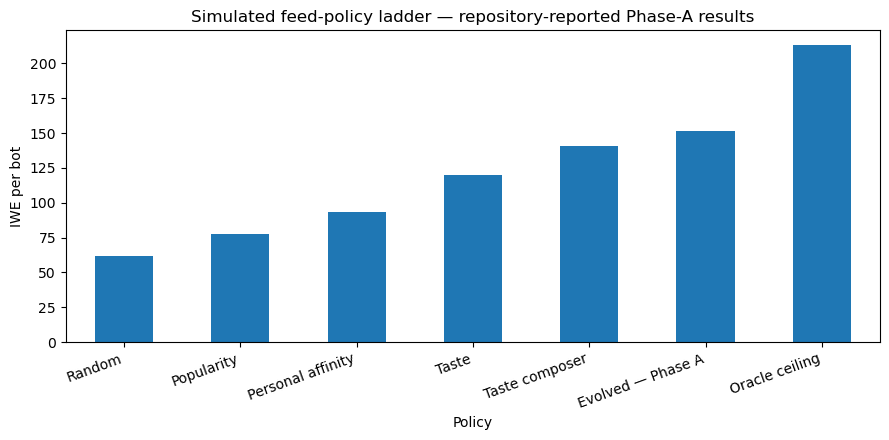

In [4]:
# Repository-reported Phase-A policy ladder.
# The Phase-2/4 ladder used the earlier ranker and has slightly different results.
import pandas as pd
import matplotlib.pyplot as plt

policy_ladder = pd.DataFrame([
    {"Policy": "Random", "IWE per bot": 61.86, "Oracle gap closed": 0.00},
    {"Policy": "Popularity", "IWE per bot": 77.87, "Oracle gap closed": 0.11},
    {"Policy": "Personal affinity", "IWE per bot": 93.64, "Oracle gap closed": 0.21},
    {"Policy": "Taste", "IWE per bot": 120.26, "Oracle gap closed": 0.39},
    {"Policy": "Taste composer", "IWE per bot": 140.44, "Oracle gap closed": 0.52},
    {"Policy": "Evolved — Phase A", "IWE per bot": 151.53, "Oracle gap closed": 0.59},
    {"Policy": "Oracle ceiling", "IWE per bot": 213.10, "Oracle gap closed": 1.00},
])
display(policy_ladder)
ax = policy_ladder.plot(x="Policy", y="IWE per bot", kind="bar", legend=False, figsize=(9, 4.5))
ax.set_title("Simulated feed-policy ladder — repository-reported Phase-A results")
ax.set_ylabel("IWE per bot")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

### 12.1 Interpreting the policy results

In the Phase-A ladder, the evolved policy reaches **151.53 IWE per bot**, compared with 61.86 for random and 213.10 for the oracle ceiling. The status report states that the evolved policy closes approximately 59% of the personalized-oracle gap.

The same report records catalog coverage improving from about 75% to 82%, category entropy from 3.35 to 3.65 bits, and repeat exposure decreasing from 0.57% to 0.52%. These guardrails matter because a single scalar score can hide undesirable narrowing of content.

An oracle is an optimistic upper bound. It should not be presented as an achievable production strategy.

## 13. Composer generations and negative results

The composer tests small, controlled adjustments to the ranking order. Each change is treated as a hypothesis and evaluated with paired-bootstrap IWE gains and guardrails.

The repository's Phase-3 report records:
- **Keep category diversity (`alpha`)**: gain around +4.45 IWE.
- **Keep session affinity (`eta`)**: gain around +8.98 IWE.
- **Reject seen-item penalty (`gamma`)**: approximately −0.01 IWE.
- **Reject cold-item bonus (`beta`)**: approximately −1.04 IWE.
- **Reject epsilon exploration (`epsilon`)**: approximately −2.34 IWE and a guardrail regression.
- **Reject length-adaptive diversity alone**: reported substantial IWE reduction.

This is an important experimental result: intuitive recommender heuristics are not automatically beneficial. The system keeps only changes supported by the stated evidence and guardrail criteria.

## 14. Evolution strategy

The final policy search uses a **(1 + λ)-evolution strategy** over 16 parameters: seven composer controls, five ranking-score weights and four retrieval counts. The search perturbs a parent configuration, evaluates candidate policies, retains improvements and reduces perturbation scale as the search proceeds.

To reduce overfitting, evaluation is staged:
- **TRAIN:** explore candidate configurations with a smaller simulation budget.
- **VALIDATION:** select a candidate with a larger budget.
- **TEST:** run the final comparison once on a held-out simulation setup.

Fitness combines IWE with penalties for guardrail degradation. The status report records a Phase-4 test gain of +13.53 IWE, with paired 95% confidence interval [+12.10, +14.92]. The Phase-A ladder later reports evolved at 151.53 IWE per bot; this is a separate experiment version from the earlier 149.54 result.

## 15. Reproducibility: original project commands

The repository's experiment drivers are the source of truth for reproducing training and simulation. The original demo notebook is designed to run top-to-bottom with inline graphs. The following commands are documented in the repository; full runs require the appropriate local Python dependencies, prepared artifacts and access to the raw KuaiSAR-v2 data.

```bash
cd recommender-engine
python -m pytest -q
python run_offline.py --fast
python run_swarm.py
python run_generations.py
python run_evolve.py
python -m feed.plotting
```

The preparation pipeline is implemented in `prepare_data.py` and `feed/build.py`. Data and model artifacts are not guaranteed to exist in a fresh checkout; follow the repository configuration and data access instructions before running the pipeline.

This report deliberately does not claim that these commands were run during report generation. The benchmark tables and plots above are transcribed from the public README and phase status report.

## 16. Limitations and threats to validity

1. **Observational interactions:** user actions are not randomised; engagement does not equal satisfaction.
2. **Watch-time proxy:** longer watch may indicate interest but is not direct evidence of benefit.
3. **Unobserved search actions:** missing downstream labels must remain masked rather than treated as negative.
4. **Short observation period:** around 19.1 days does not establish long-term habit change or durable retention.
5. **Cold-start trade-off:** k-core filtering removes much of the item tail; cold-start behaviour remains important.
6. **Imperfect calibration:** 7 of 12 calibration targets meet the 15% band; five structural misses remain documented.
7. **Simulator dependence:** paired comparisons reduce noise but do not make synthetic outcomes causal evidence about real people.
8. **Oracle interpretation:** the oracle is an upper bound, not a deployable recommender.
9. **Versioned metrics:** model size and policy values differ between early and final phases; each number must be tied to its run.
10. **Ethical framing:** engagement optimisation can amplify repetitive or compulsive consumption. A real deployment should define user-benefit goals, enforce controls and audit effects rather than optimise time spent alone.

## 17. Conclusion

Doomscroll is an end-to-end recommender-systems study linking EDA, leakage-aware feature engineering, graded engagement ranking, synthetic-user modelling, calibration, policy composition and evolutionary search.

The final wide TasteNet reports a test NDCG@10 of 0.5332, outperforming popularity at 0.4976 with a paired-bootstrap confidence interval that excludes zero. In the Phase-A simulator ladder, the evolved policy reaches 151.53 IWE per bot, improves selected coverage/diversity/repeat-exposure guardrails, and closes approximately 59% of the personalized-oracle gap.

The correct conclusion is carefully scoped: these are relative systems improvements under a documented, calibrated-but-imperfect simulator. They are not proof that the system improves the well-being of real users. The project's strengths include an end-to-end experimental loop, temporally valid evaluation, explicit uncertainty, documented calibration misses and preservation of negative results.

## References

1. [Doomscroll repository README](https://github.com/1ens0r/doomscroll/blob/main/README.md)
2. [Build status and phase-by-phase results](https://github.com/1ens0r/doomscroll/blob/main/status.md)
3. [Original executed demo notebook](https://github.com/1ens0r/doomscroll/blob/main/demo.ipynb)
4. [EDA notebooks and committed figures](https://github.com/1ens0r/doomscroll/tree/main/eda)
5. [Recommender engine source](https://github.com/1ens0r/doomscroll/tree/main/recommender-engine)
6. [Project notes and calibration documentation](https://github.com/1ens0r/doomscroll/tree/main/notes)

---

**Submission note:** This notebook is formatted as a self-contained report. The included benchmark outputs are labelled as repository-reported values. To claim a fresh experimental reproduction, the raw data and full project environment must be available and the original pipeline must be executed.